# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [18]:
import pandas as pd
import numpy as np
import os
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("data/temps.csv")

In [19]:
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


In [20]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    object 
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), object(1)
memory usage: 24.6+ KB


In [21]:
df.describe()

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [34]:

df = pd.read_csv("data/temps.csv")

required = {
    "year", "month", "day", "week",
    "temp_2", "temp_1", "average", "actual", "friend"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")

numeric_cols = [
    "year", "month", "day",
    "temp_2", "temp_1", "average", "actual", "friend"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# `day` es el día del mes; la fecha se construye con año, mes y día.
df["date"] = pd.to_datetime(df[["year", "month", "day"]], errors="coerce")

print("Dimensiones:", df.shape)
display(df.head())
display(df.dtypes.to_frame("tipo"))
display(df.isna().sum().sort_values(ascending=False).to_frame("nulos"))
print("Filas duplicadas:", df.duplicated().sum())
print("Fechas duplicadas:", df["date"].duplicated().sum())

# Comprueba que mes y día del año sean coherentes.
month = pd.to_numeric(df["month"], errors="coerce")
valid_dates = df["date"].notna() & month.notna()
print(
    "Meses que no coinciden con la fecha:",
    (df.loc[valid_dates, "date"].dt.month != month.loc[valid_dates]).sum(),
)

display(df[numeric_cols].describe().T)

Dimensiones: (348, 10)


,year,month,day,week,temp_2,temp_1,average,actual,friend,date
0,2016,1,1,Fri,45,45,45.6,45,29,2016-01-01
1,2016,1,2,Sat,44,45,45.7,44,61,2016-01-02
2,2016,1,3,Sun,45,44,45.8,41,56,2016-01-03
3,2016,1,4,Mon,44,41,45.9,40,53,2016-01-04
4,2016,1,5,Tues,41,40,46.0,44,41,2016-01-05


,tipo
year,int64
month,int64
day,int64
week,object
temp_2,int64
temp_1,int64
average,float64
actual,int64
friend,int64
date,datetime64[ns]


,nulos
year,0
month,0
day,0
week,0
temp_2,0
temp_1,0
average,0
actual,0
friend,0
date,0


Filas duplicadas: 0
Fechas duplicadas: 0
Meses que no coinciden con la fecha: 0


,count,mean,std,min,25%,50%,75%,max
year,348.0,2016.000000,0.000000,2016.0,2016.000,2016.0,2016.000,2016.0
month,348.0,6.477011,3.498380,1.0,3.000,6.0,10.000,12.0
day,348.0,15.514368,8.772982,1.0,8.000,15.0,23.000,31.0
temp_2,348.0,62.652299,12.165398,35.0,54.000,62.5,71.000,117.0
temp_1,348.0,62.701149,12.120542,35.0,54.000,62.5,71.000,117.0
average,348.0,59.760632,10.527306,45.1,49.975,58.2,69.025,77.4
actual,348.0,62.543103,11.794146,35.0,54.000,62.5,71.000,92.0
friend,348.0,60.034483,15.626179,28.0,47.750,60.0,71.000,95.0


### 3. Selecciona variables y divide en train y test

In [23]:

# `actual` es el valor a predecir; year es constante y week requiere codificación.
features = ['month', 'day', 'temp_2', 'temp_1', 'average', 'friend']
X = df[features]
y = df['actual']

# Al ser una serie temporal, reservamos los últimos días para test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print(f'Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas')

Train: 278 filas | Test: 70 filas


### 4. Entrena el modelo


In [24]:

model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Modelo entrenado con {model.n_features_in_} variables.')

Modelo entrenado con 6 variables.


### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [25]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R²: {r2:.4f}')
print(f'MAE: {mae:.4f}')
print(f'MAPE: {mape:.2f}%')
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')

R²: 0.5056
MAE: 5.1714
MAPE: 10.19%
MSE: 40.0857
RMSE: 6.3313


### 6. Representa el árbol de decisión

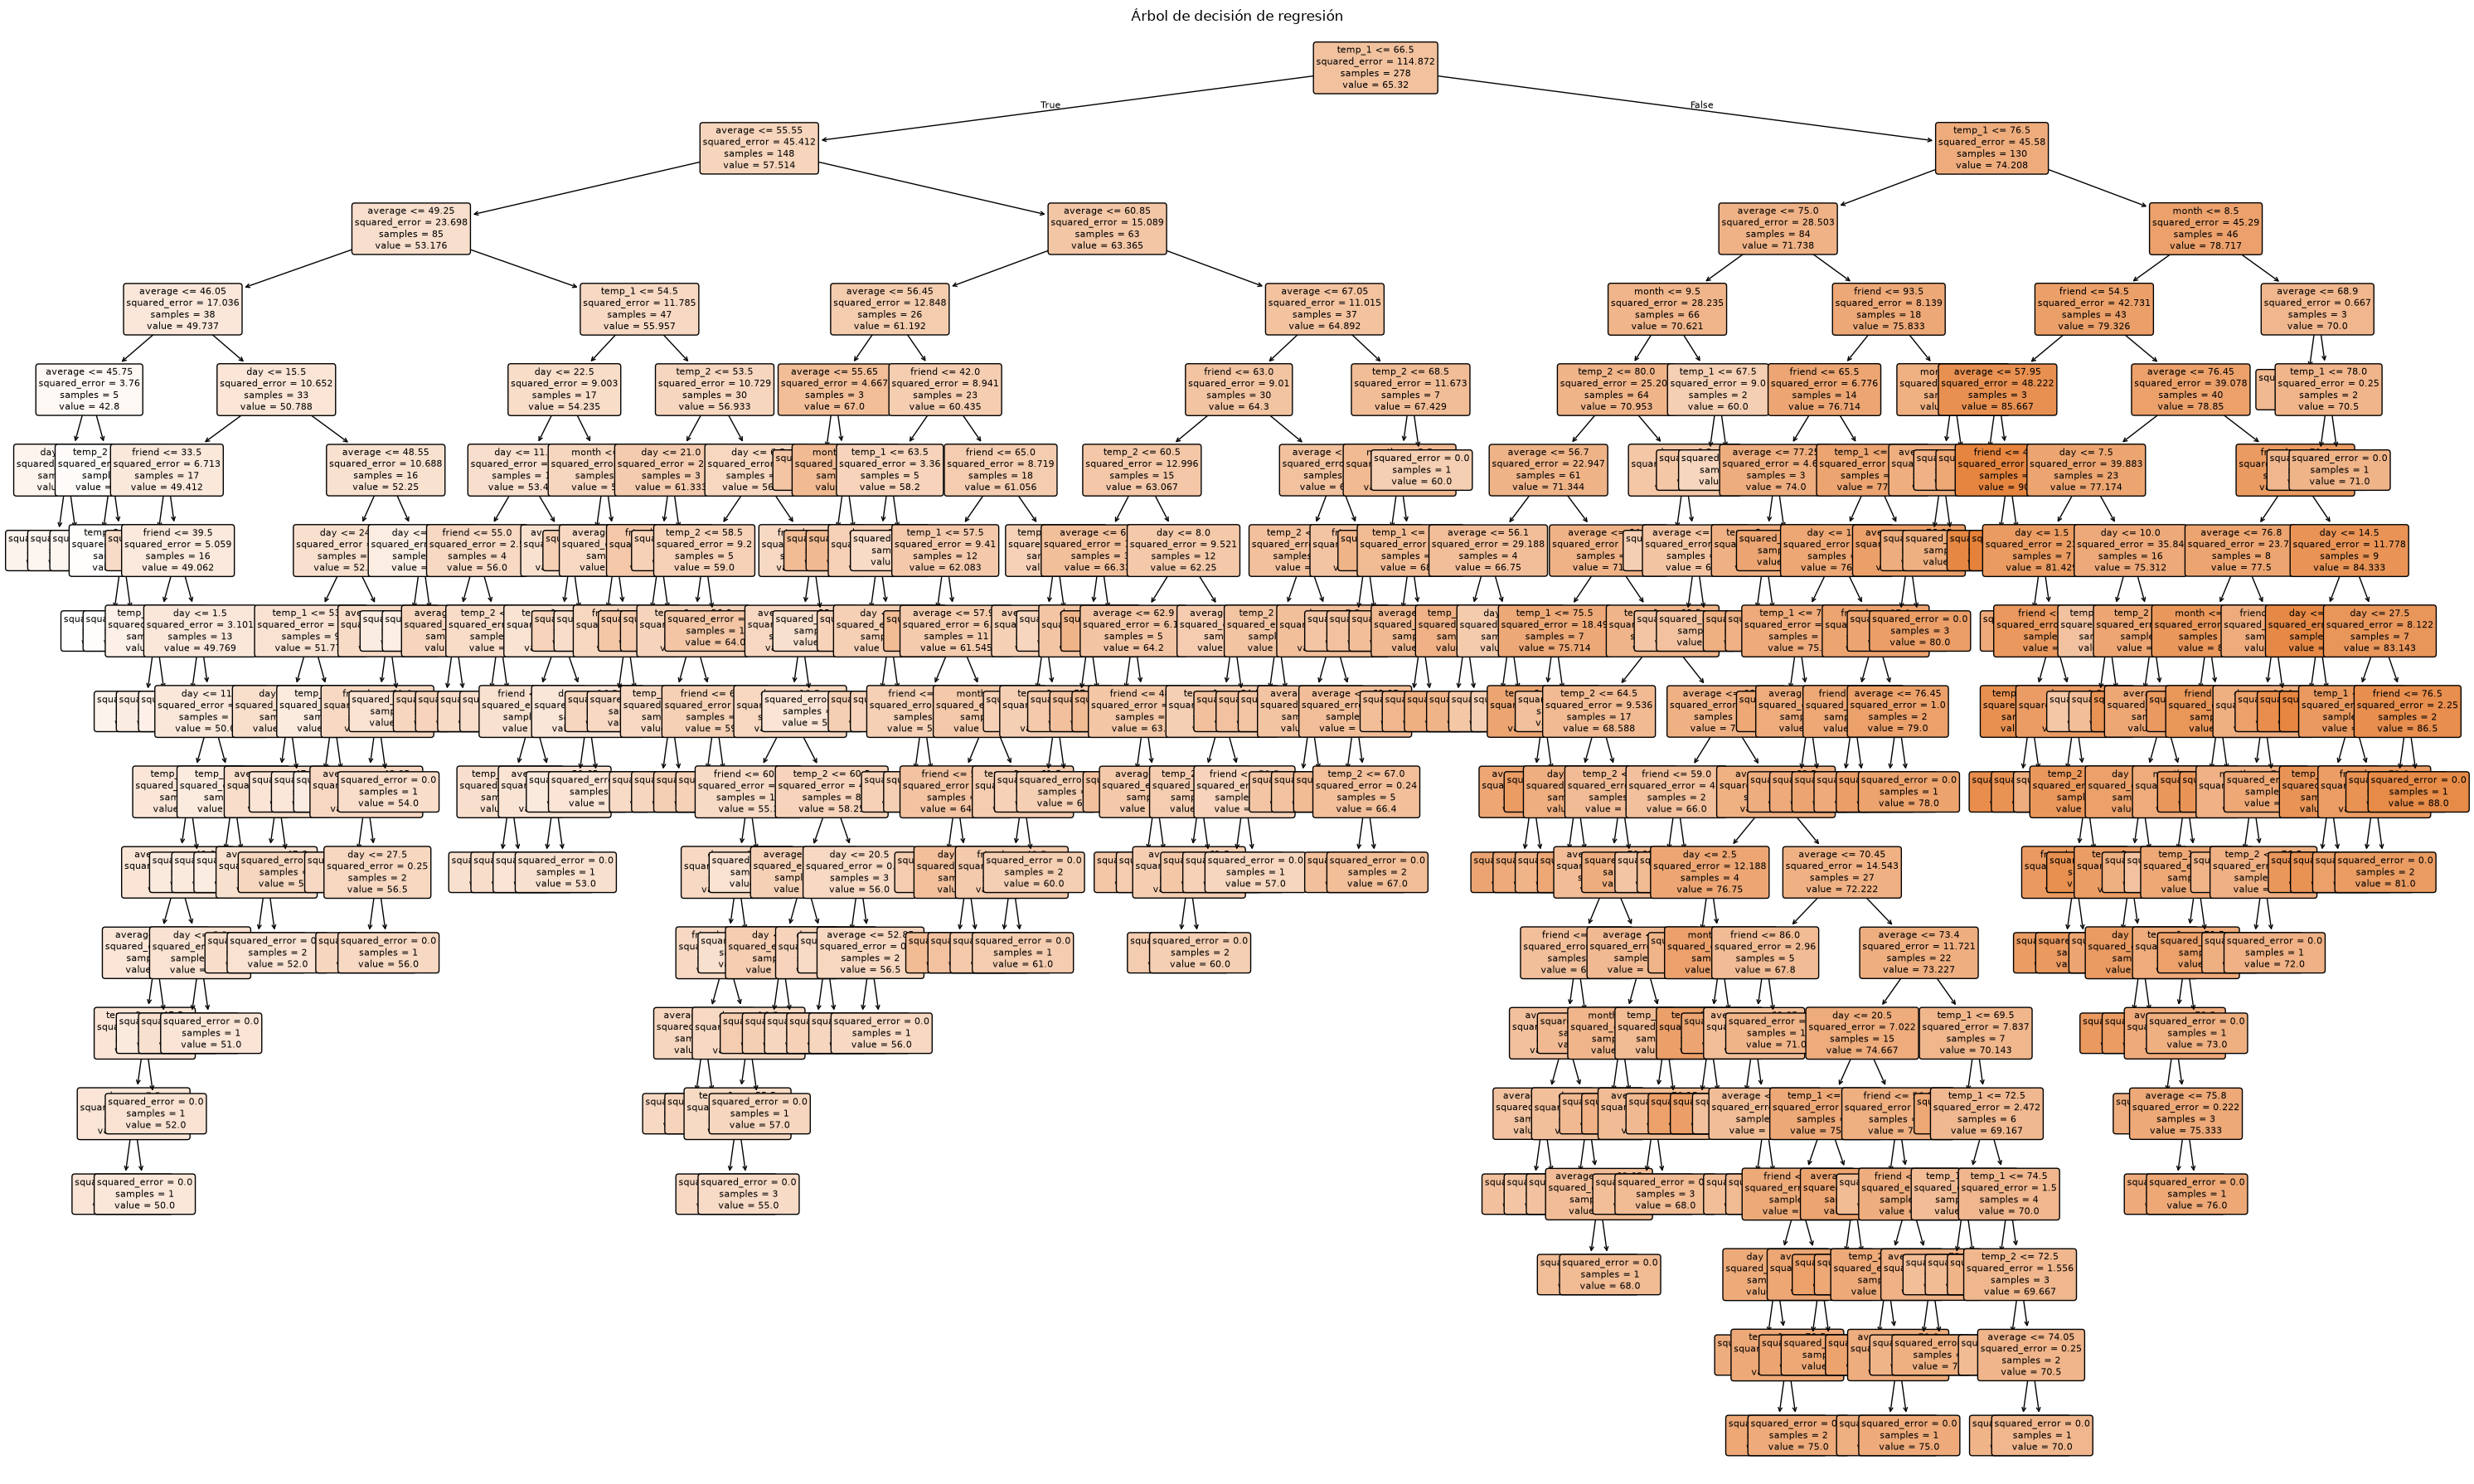

In [26]:

plt.figure(figsize=(30, 18))
plot_tree(
    model,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title('Árbol de decisión de regresión')
plt.tight_layout()
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [27]:
model = DecisionTreeRegressor(max_depth=3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Modelo reentrenado: profundidad {model.get_depth()}.')

Modelo reentrenado: profundidad 3.


### 8. Vuelve a evaluar tu modelo

In [28]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R²: {r2:.4f}')
print(f'MAE: {mae:.4f}')
print(f'MAPE: {mape:.2f}%')
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')

R²: 0.4611
MAE: 5.1737
MAPE: 11.07%
MSE: 43.6928
RMSE: 6.6101


### 9. Vuelve a representar su árbol

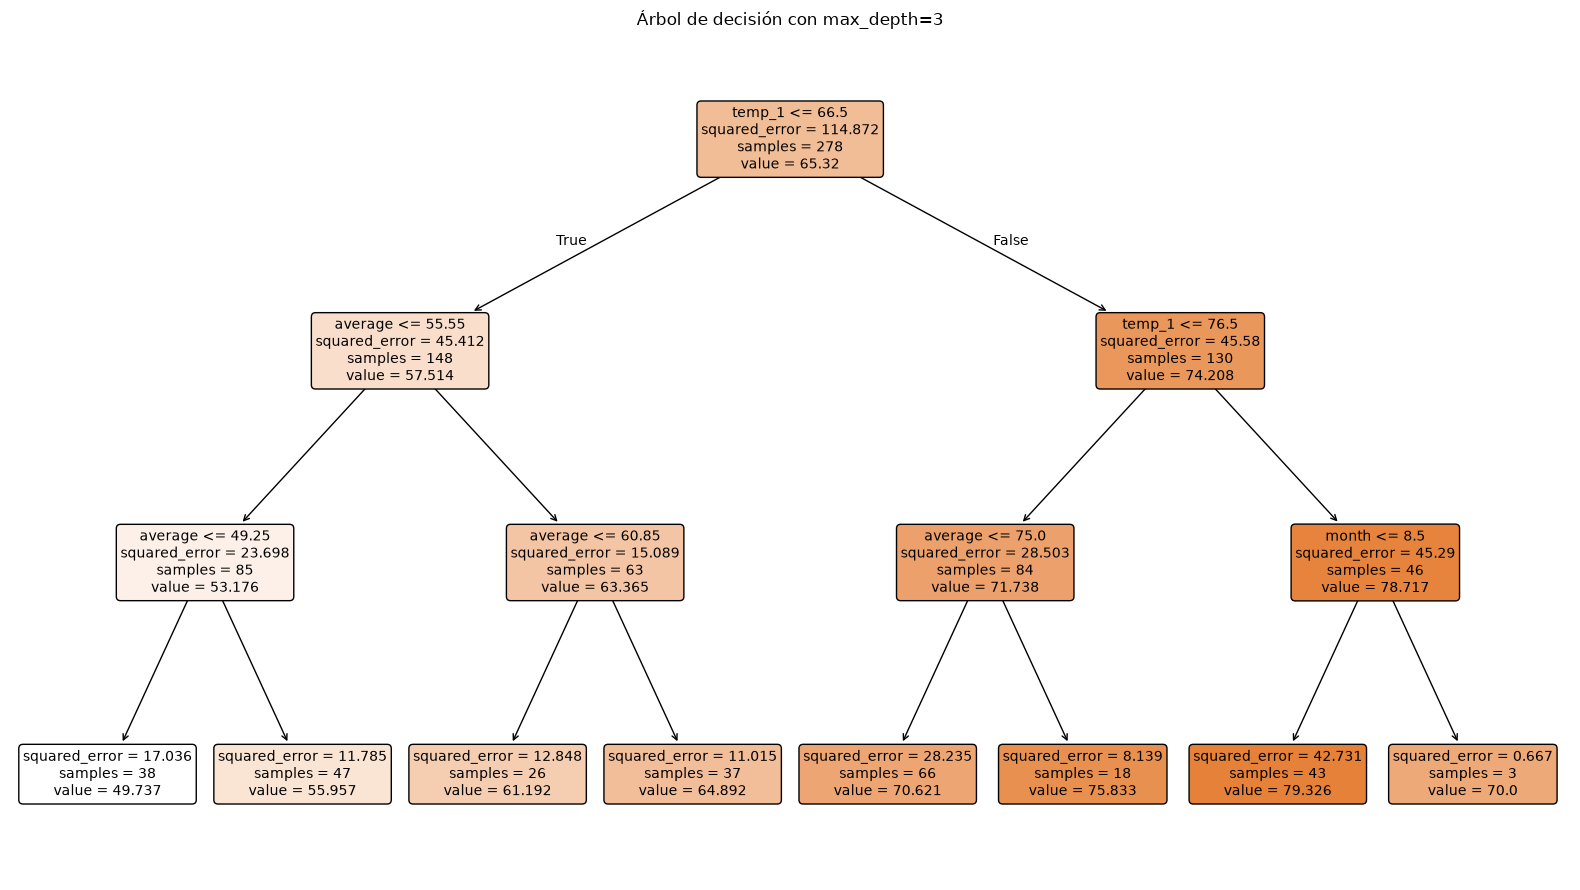

In [29]:

plt.figure(figsize=(16, 9))
plot_tree(
    model,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title('Árbol de decisión con max_depth=3')
plt.tight_layout()
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [30]:

param_grid = {
    'max_depth': [None, 3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=TimeSeriesSplit(n_splits=5),
)
grid_search.fit(X_train, y_train)

model = grid_search.best_estimator_
y_pred = model.predict(X_test)

print(f'Mejores hiperparámetros: {grid_search.best_params_}')
print(f'MAE medio en validación cruzada: {-grid_search.best_score_:.4f}')
print(f'MAE en test: {mean_absolute_error(y_test, y_pred):.4f}')

Mejores hiperparámetros: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 10}
MAE medio en validación cruzada: 5.1140
MAE en test: 5.2781


### 11. Obten el `feature_importances` de cada variable en el último modelo

In [31]:
feature_importances = pd.Series(
    model.feature_importances_, index=features
).sort_values(ascending=False)

print(feature_importances.to_string())

temp_1     0.795896
average    0.204104
day        0.000000
month      0.000000
temp_2     0.000000
friend     0.000000


### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [54]:

y_clf = (df['actual'] > 59).astype(int)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X, y_clf, test_size=0.2, shuffle=False
)

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [3, 5, None]},
    cv=TimeSeriesSplit(n_splits=5),
)
grid.fit(X_train_clf, y_train_clf)

best_classifier = grid.best_estimator_
print('Mejores parámetros:', grid.best_params_)
print(f'Accuracy CV: {grid.best_score_:.3f}')
print(f'Accuracy test: {grid.score(X_test_clf, y_test_clf):.3f}')

Mejores parámetros: {'max_depth': 3}
Accuracy CV: 0.852
Accuracy test: 0.886


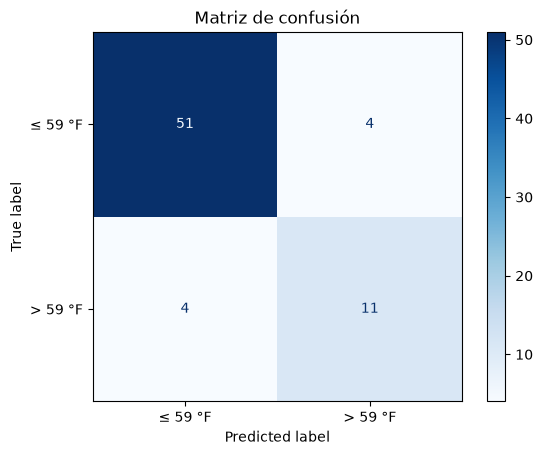

In [51]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_clf,
    y_clf_pred,
    display_labels=["≤ 59 °F", "> 59 °F"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión")
plt.show()

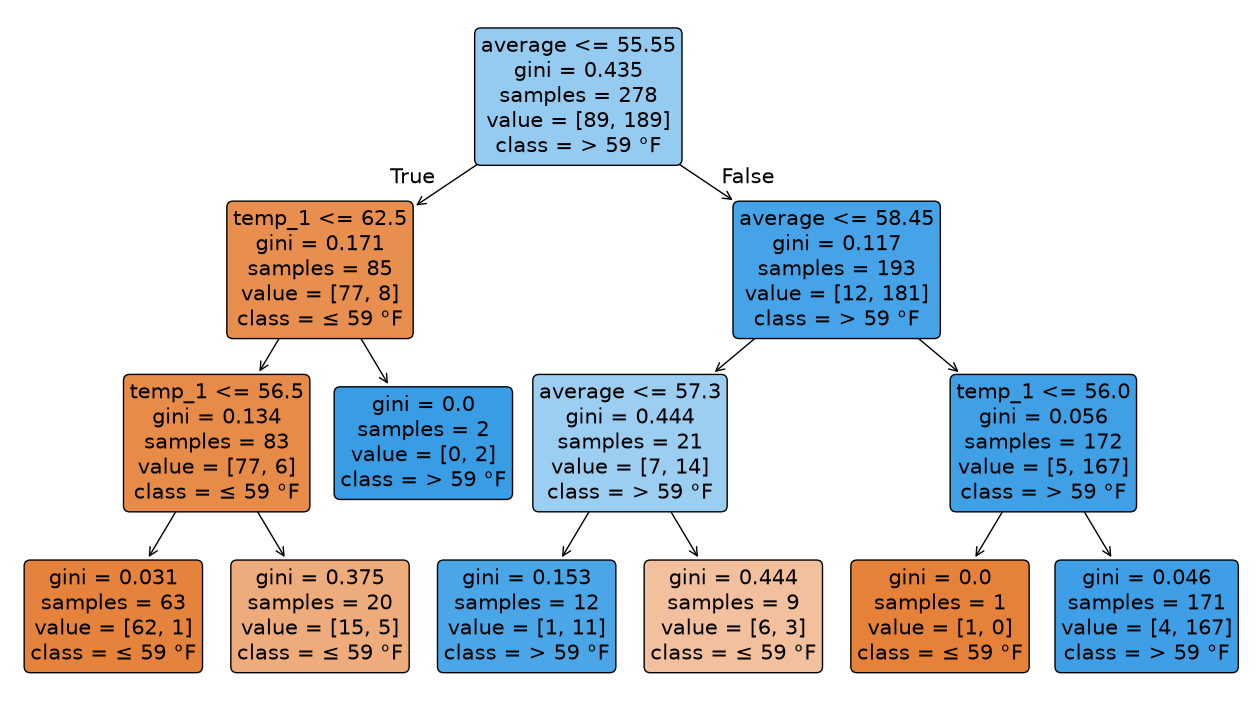

In [48]:

plt.figure(figsize=(16, 9))
plot_tree(
    best_classifier,
    feature_names=features,
    class_names=["≤ 59 °F", "> 59 °F"],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False
    
)
plt.show()

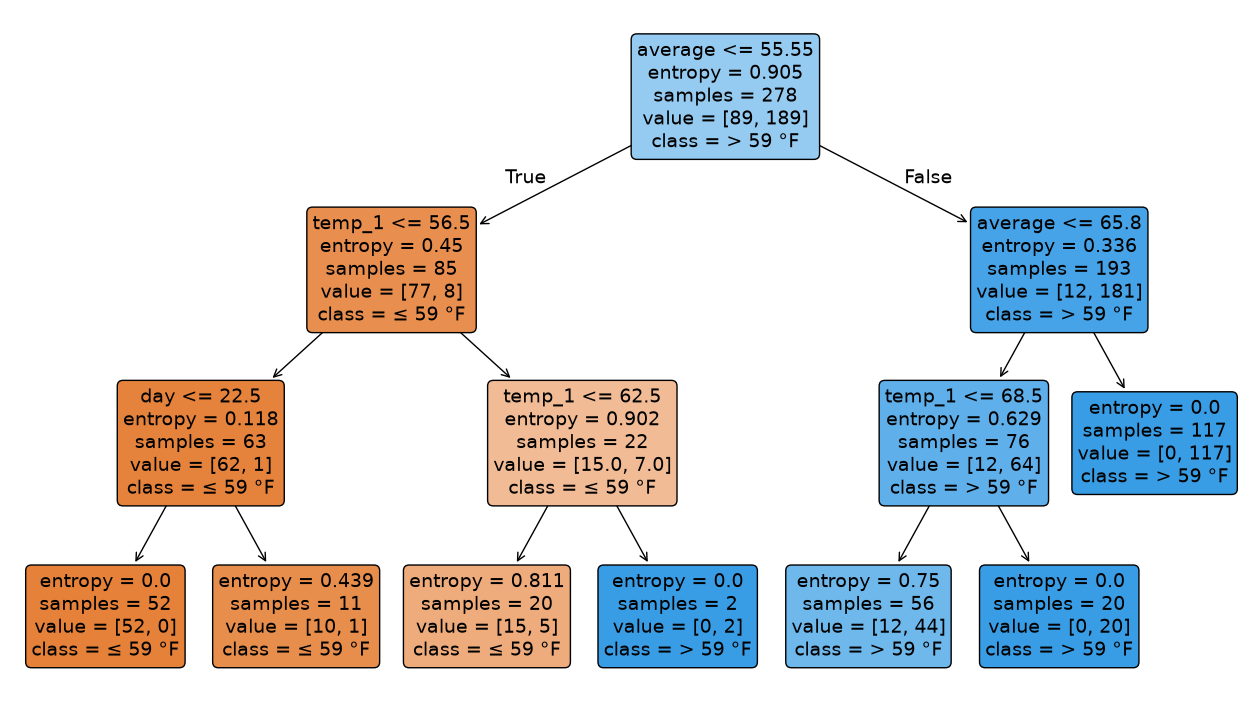

In [56]:

entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42
)
entropy_tree.fit(X_train_clf, y_train_clf)

plt.figure(figsize=(16, 9))
plot_tree(
    entropy_tree,
    feature_names=features,
    class_names=["≤ 59 °F", "> 59 °F"],
    filled=True,
    rounded=True
)
plt.show()

### ANALISIS DEFINITIVO Y CONCLUSIONES

El CSV contiene 348 registros de temperaturas de Seattle en 2016 y 9 columnas originales. No se encontraron nulos ni filas o fechas duplicadas.

Year es constante, por lo que se excluyó. week es texto y no se incluyó en los modelos finales.

Se corrigió la comprobación de fechas: day representa el día del mes, así que la fecha se construye con year, month y day. 

La comprobación corregida no encuentra fechas inválidas ni discrepancias entre mes y fecha. Hay 18 días del año sin registro.

Las variables de entrada fueron month, day, temp_2, temp_1, average y friend; el objetivo de regresión fue actual.

Se separaron los datos en orden cronológico: 278 para entrenamiento y 70 para test.

Modelos de Regresión

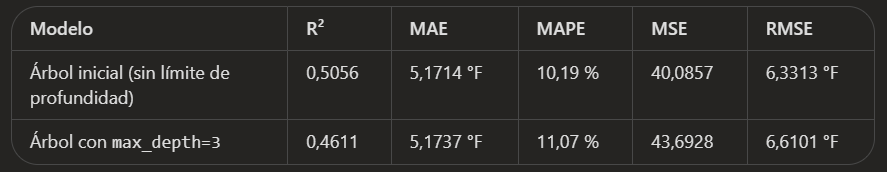

Después, GridSearchCV con 5 particiones temporales seleccionó max_depth=3, min_samples_leaf=4 y min_samples_split=10. Su MAE medio de validación fue 5,1140 °F y el MAE en test 5,2781 °F.

En ese último árbol, las importancias fueron:

temp_1: 0,7959
average: 0,2041
day, month, temp_2 y friend: 0

En árboles no hay coeficientes lineales: estas importancias indican cuánto se utilizaron las variables para dividir el árbol, no el sentido ni la causalidad de su efecto.

Regresión: el error ronda los 5 °F; el Grid Search no mejoró el resultado en test. temp_1 fue la variable más importante.

Clasificación: acertó el 88,6 % en test, pero identificó correctamente el 73 % de los días cálidos.